# Comparison charts

Bar family, dot plots, dumbbells, pictograms, radial/polar forms, parallel coordinates, waterfall, slope, small multiples, word cloud, tables and quadrants.

In [1]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning)
import pandas as pd
import pychartist as pc
import plotly.io as pio
pio.renderers.default = "plotly_mimetype+notebook_connected"   # renders in JupyterLab/VS Code/Colab; plotly.js from CDN

In [2]:
pen = pc.datasets.load('penguins'); tips = pc.datasets.load('tips'); barley = pc.datasets.load('barley')
gap = pc.datasets.load('gapminder'); g07 = gap[gap.year == 2007]

## Bars and columns
Sorted, labelled at the tip only when there are few bars; colours follow the entity.

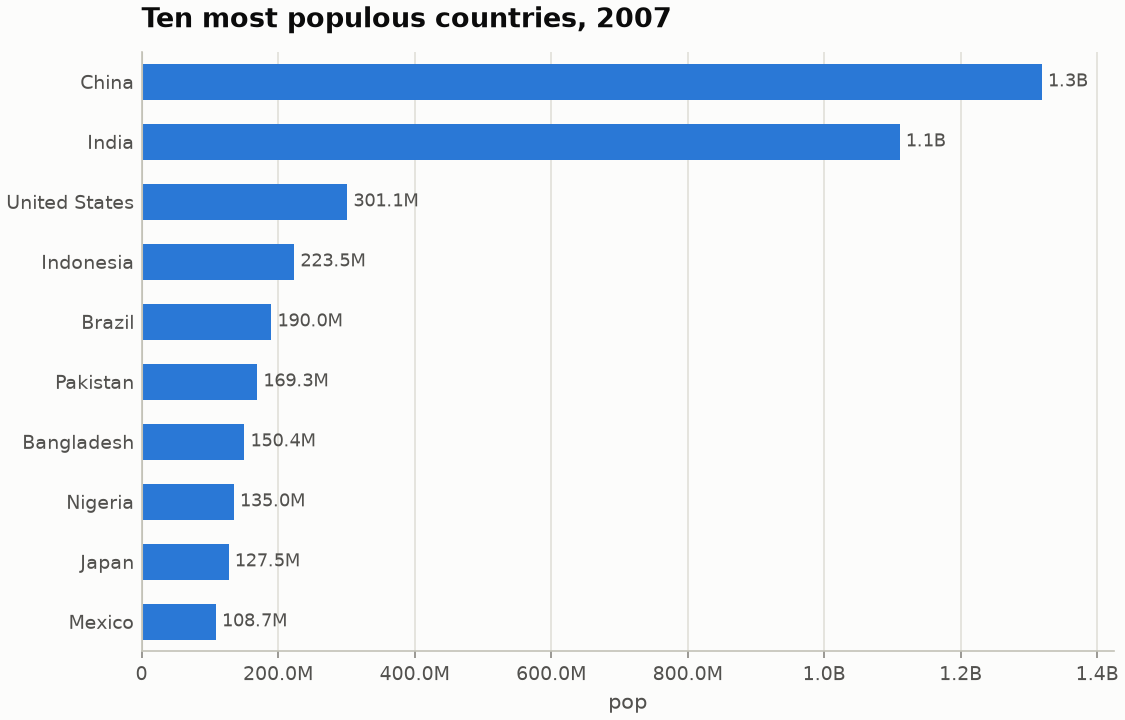

In [3]:
pc.bar(g07.nlargest(10, 'pop'), 'country', 'pop', sort='desc', title='Ten most populous countries, 2007')

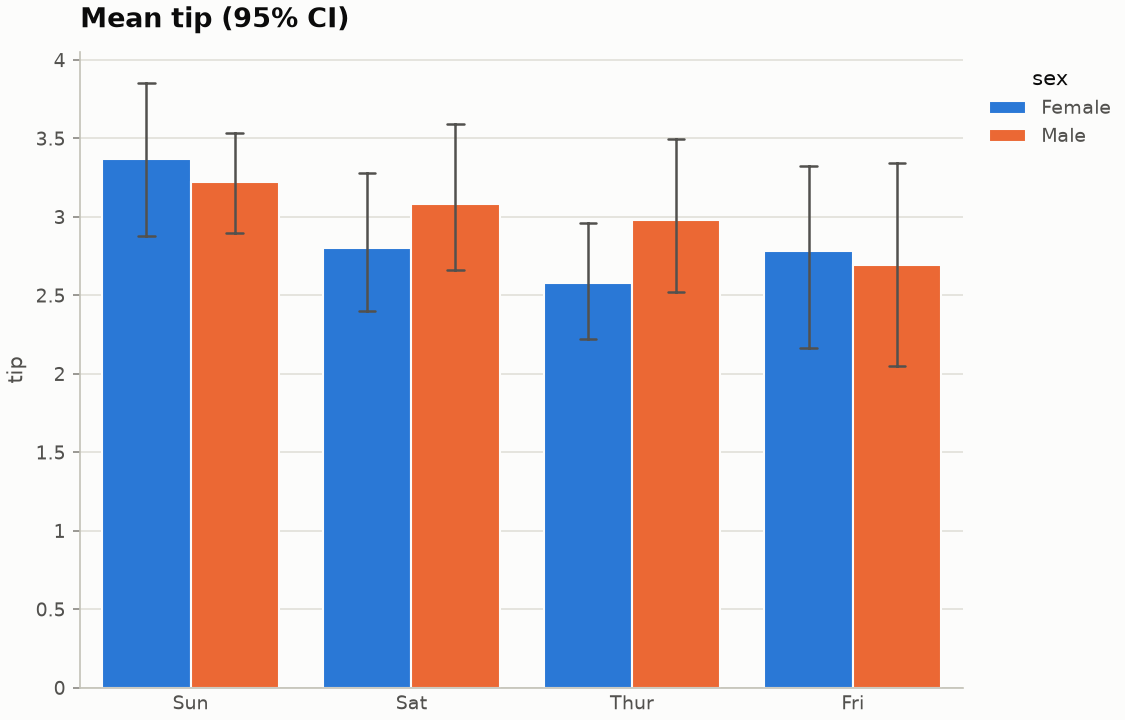

In [4]:
pc.grouped_bar(tips, 'day', 'tip', 'sex', agg='mean', backend='seaborn', title='Mean tip (95% CI)')

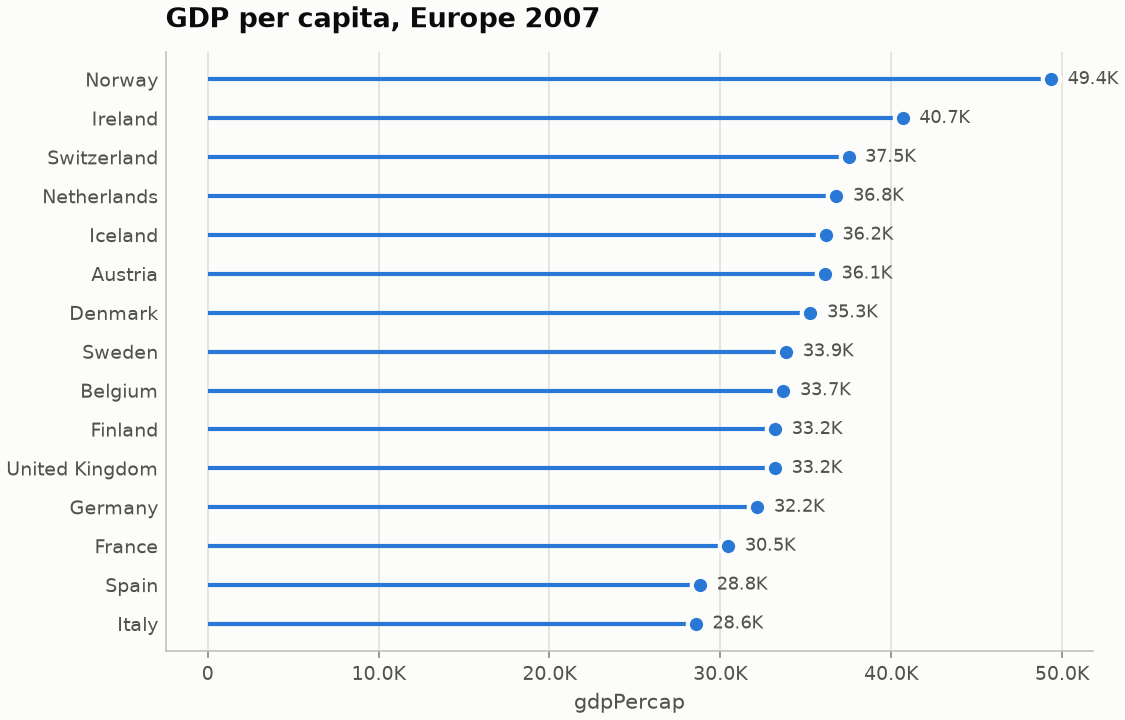

In [5]:
pc.lollipop(g07[g07.continent == 'Europe'].nlargest(15, 'gdpPercap'), 'country', 'gdpPercap', title='GDP per capita, Europe 2007')

## Paired values: dot plot, dumbbell, range, slope

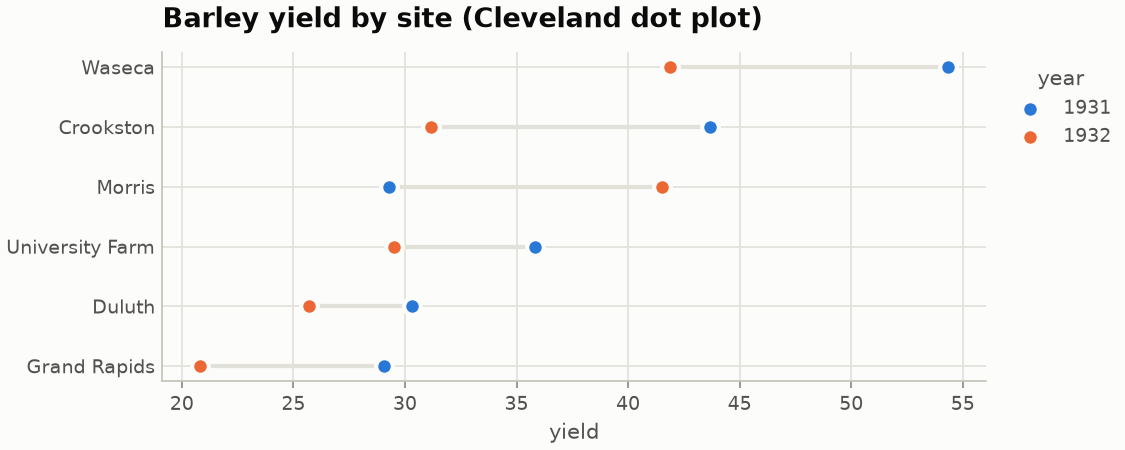

In [6]:
pc.dot_plot(barley, 'yield', 'site', 'year', title='Barley yield by site (Cleveland dot plot)')

In [7]:
pc.dumbbell(barley, 'site', 'yield', 'year', backend='plotly', title='1931 → 1932: the Morris anomaly')

<Chart kind='dumbbell' backend='plotly' theme='pychartist'>

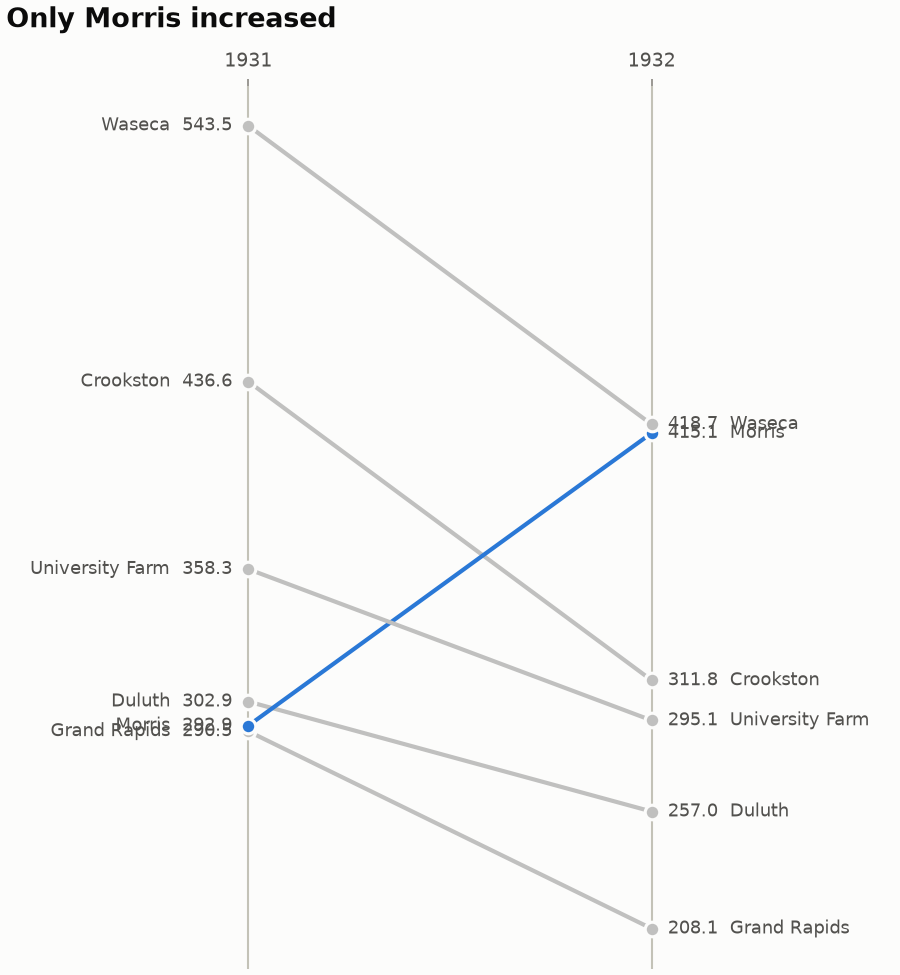

In [8]:
pc.slope(barley.groupby(['site', 'year'], as_index=False)['yield'].sum(), 'site', 'year', 'yield',
         highlight=['Morris'], title='Only Morris increased')

## Targets and changes: bullet and waterfall

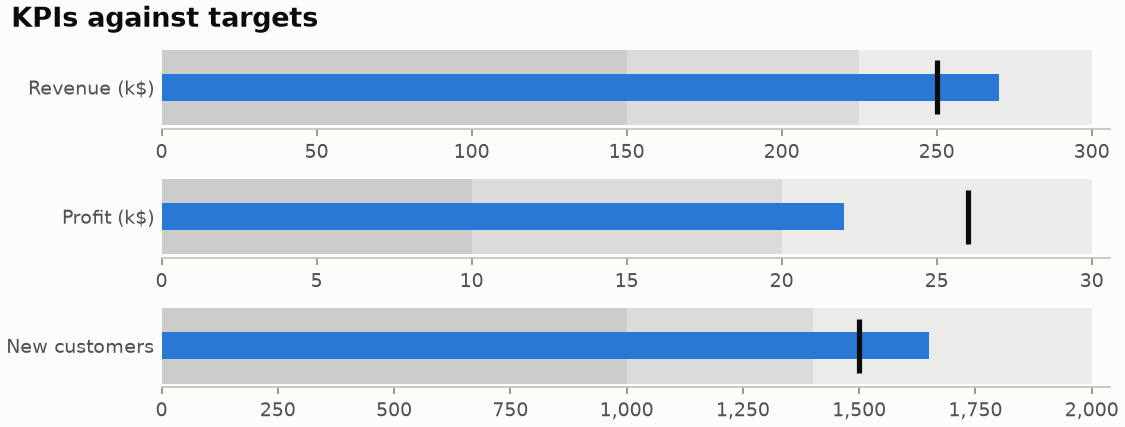

In [9]:
pc.examples.demo('bullet')

In [10]:
pc.examples.demo('waterfall', backend='plotly')

<Chart kind='waterfall' backend='plotly' theme='pychartist'>

## Icons (no SVG files needed - icons are polygons)

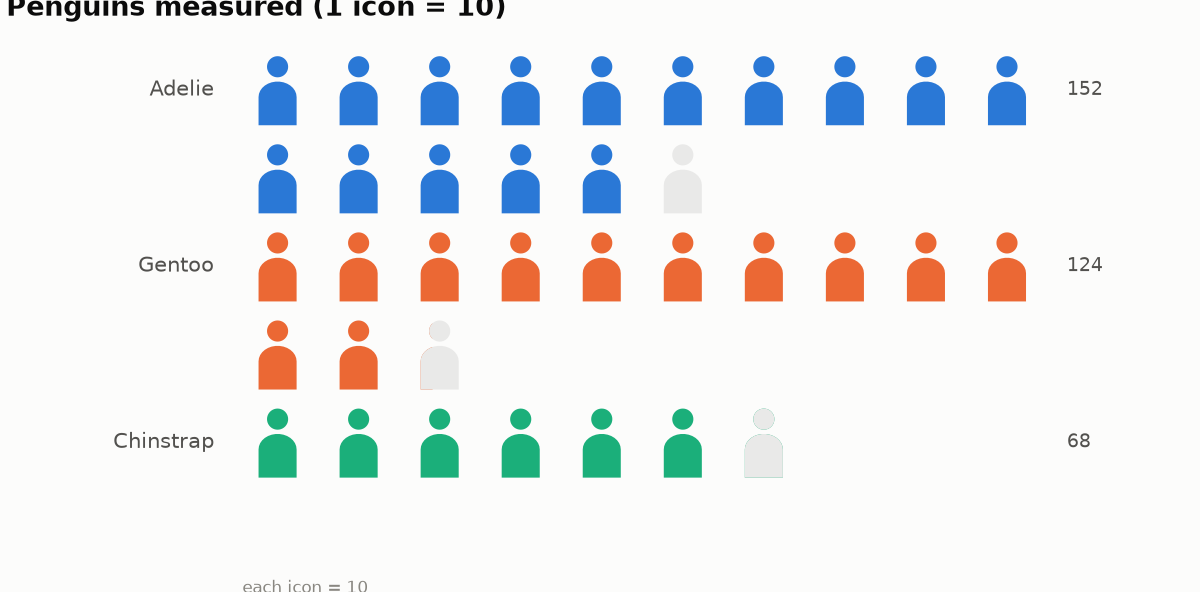

In [11]:
pc.pictogram(pen.species.value_counts().rename_axis('species').reset_index(name='n'), 'species', 'n', unit=10,
             icon='person', title='Penguins measured (1 icon = 10)')

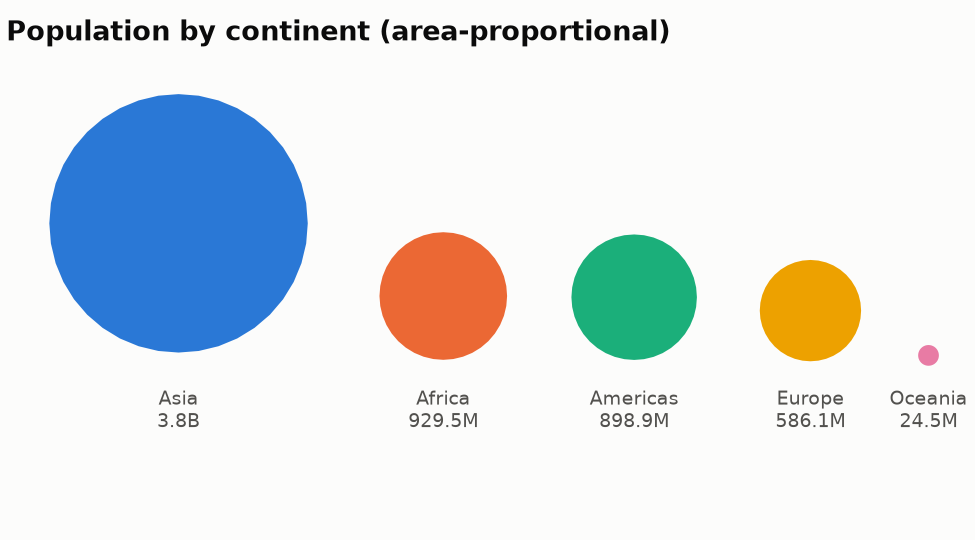

In [12]:
pc.icon_chart(g07.groupby('continent', as_index=False)['pop'].sum(), 'continent', 'pop', icon='circle',
              title='Population by continent (area-proportional)')

## Many dimensions: radar and parallel coordinates

In [13]:
dims = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']
pc.radar(pen, 'species', dims, backend='plotly', title='Species profiles')

<Chart kind='radar' backend='plotly' theme='pychartist'>

In [14]:
pc.parallel_coordinates(pen, dims, 'species', backend='plotly', title='Brush the axes to filter')

<Chart kind='parallel_coordinates' backend='plotly' theme='pychartist'>

## Circular forms (use sparingly)

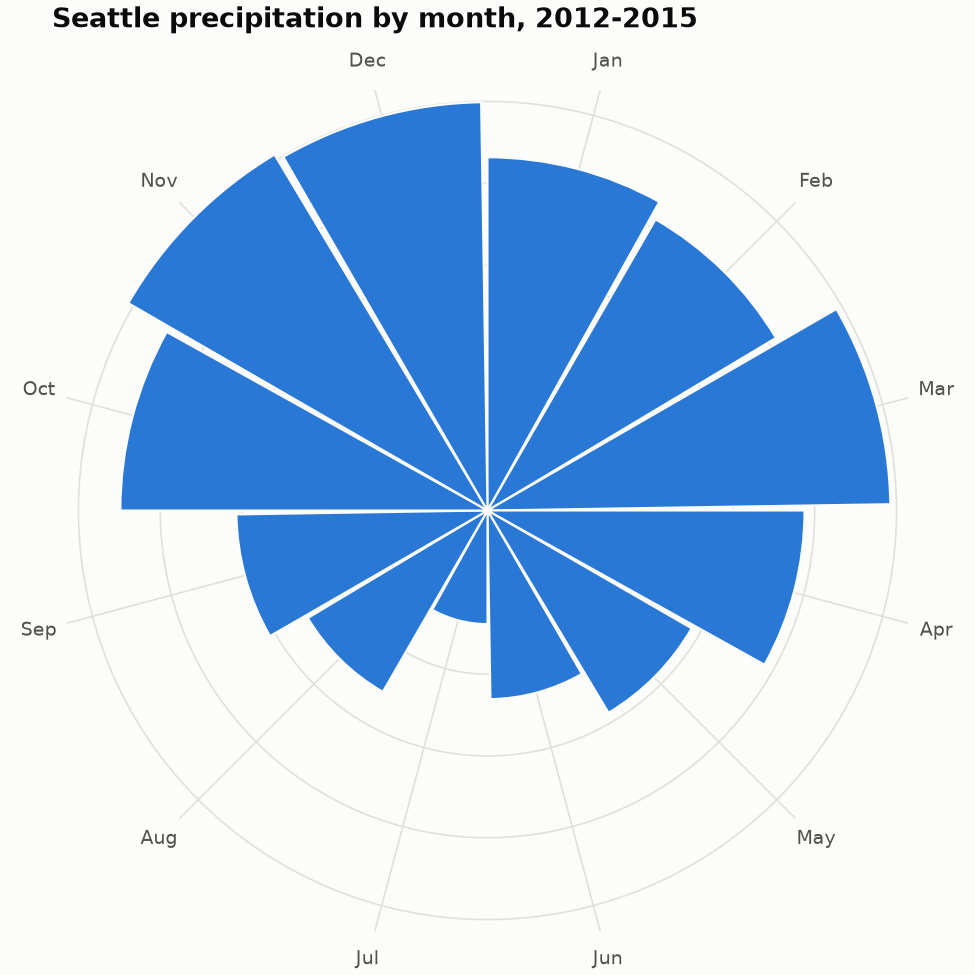

In [15]:
pc.examples.demo('nightingale')

In [16]:
pc.examples.demo('radial_bar', backend='plotly')

<Chart kind='radial_bar' backend='plotly' theme='pychartist'>

## Small multiples instead of spaghetti

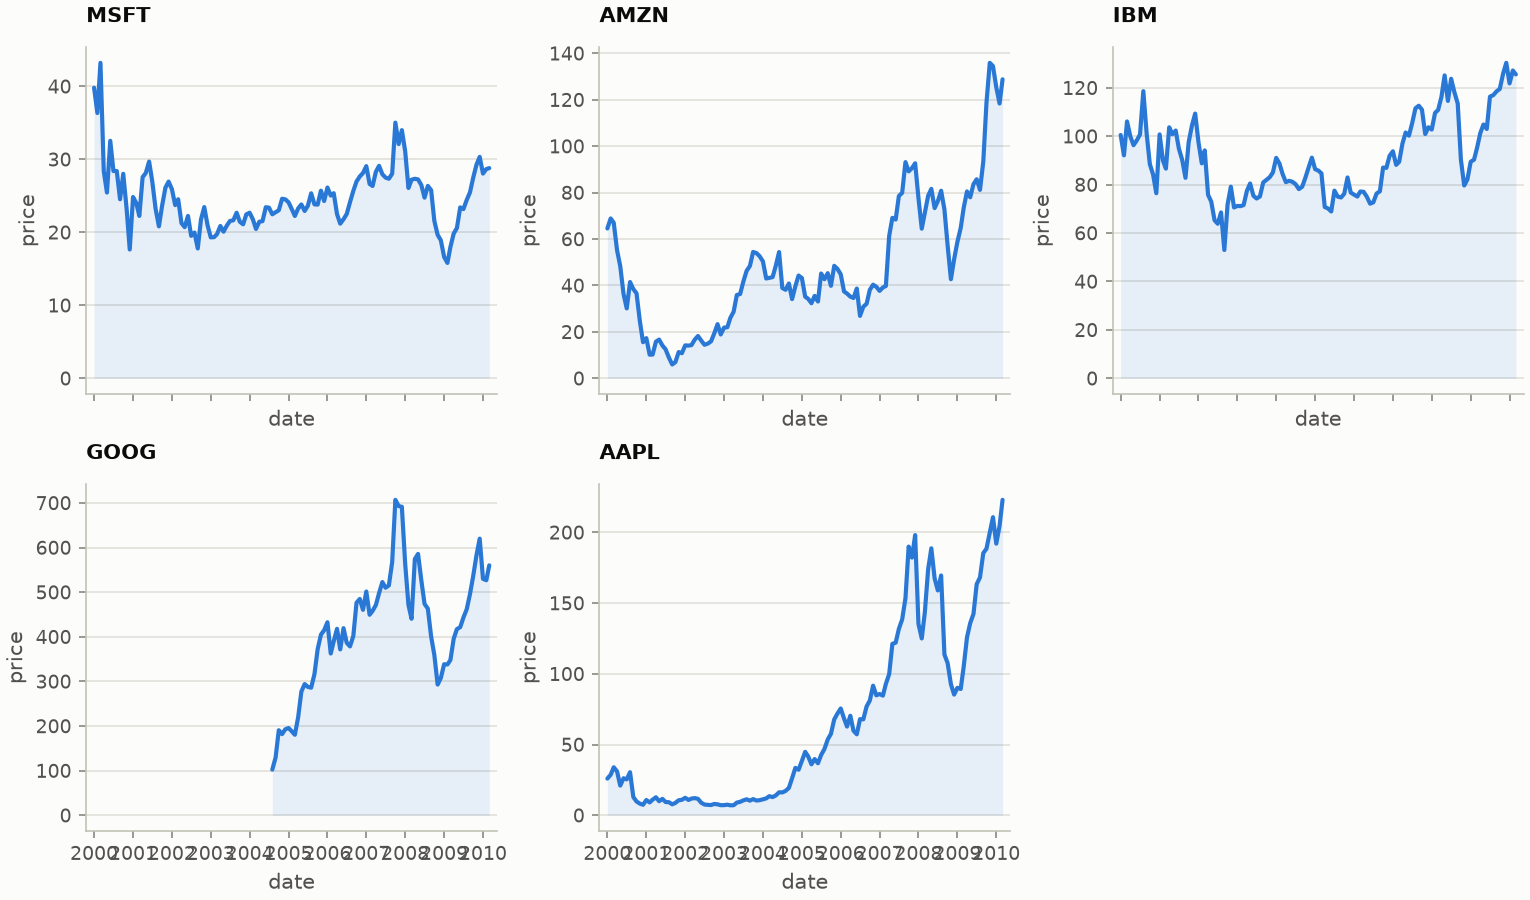

In [17]:
stocks = pc.datasets.load('stocks')
pc.small_multiples(stocks, 'symbol', 'area', x='date', y='price', cols=3, sharey=False, color_by='symbol')

## Text, tables, matrices, quadrants

        word  count
0  elizabeth    644
1      darcy    430
2     bennet    339
3    bingley    309
4       jane    300


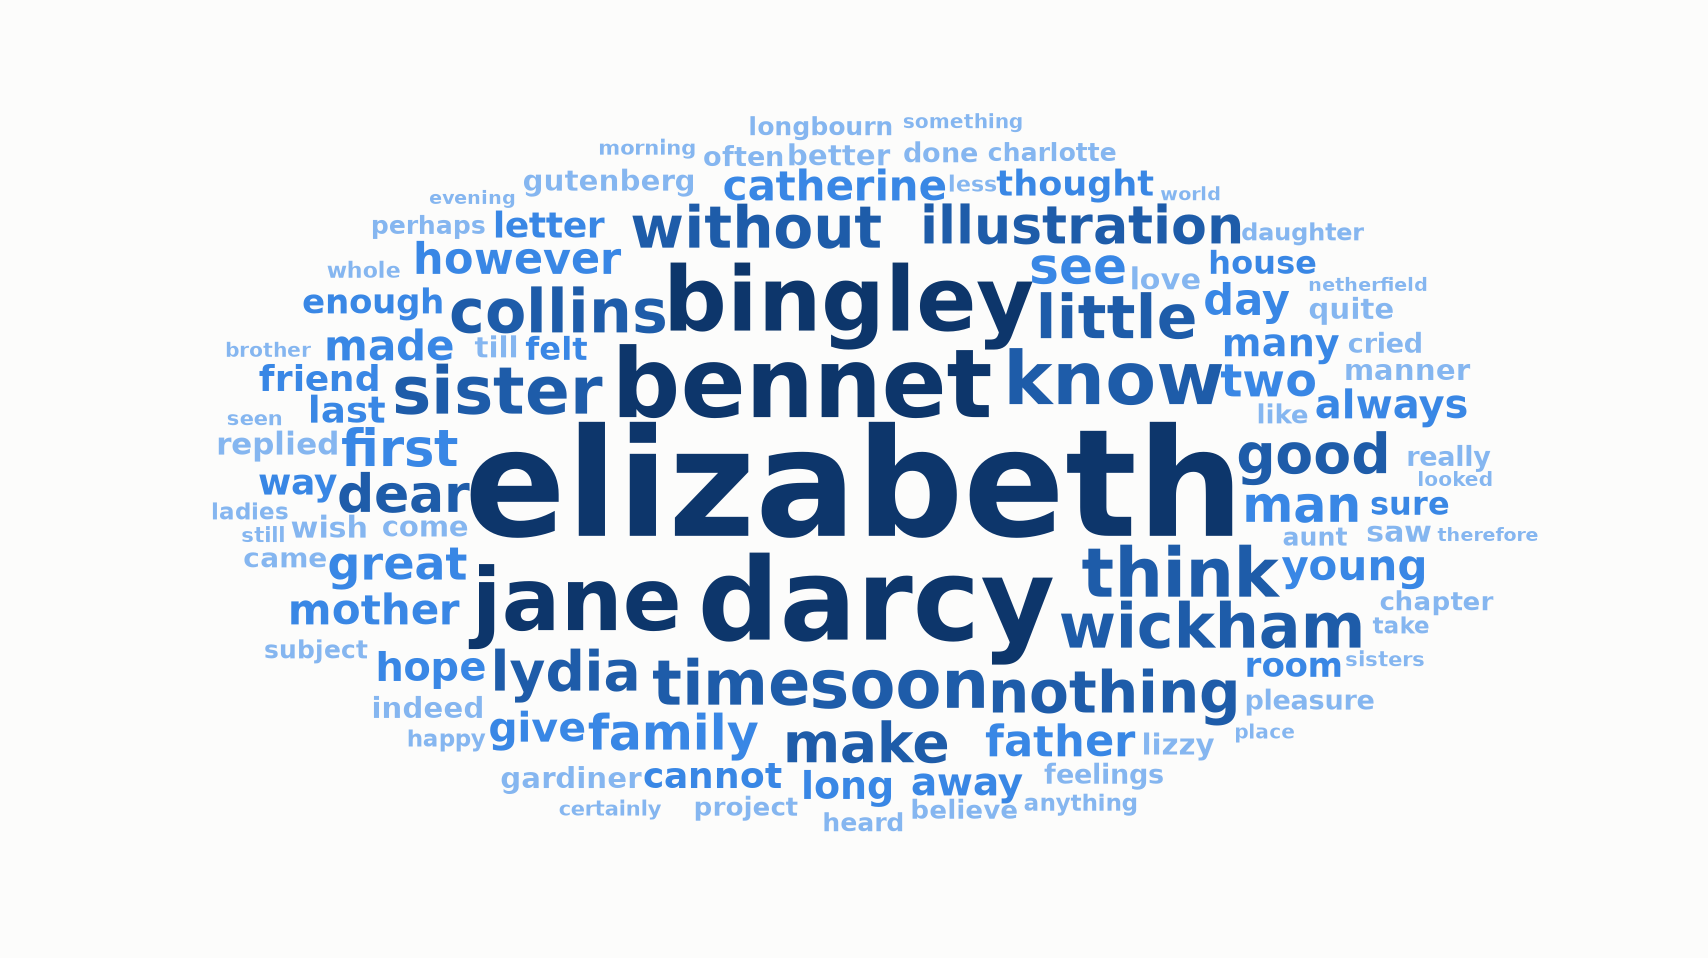

In [18]:
c = pc.word_cloud(pc.datasets.load('pride_prejudice'), max_words=100, title='Pride and Prejudice')
print(c.meta['words'].head(5)[['word', 'count']])
c

In [19]:
pc.table_chart(g07.nlargest(10, 'pop')[['country', 'pop', 'lifeExp', 'gdpPercap']], heat=['lifeExp', 'gdpPercap'],
               backend='plotly', title='Conditional formatting per column')

<Chart kind='table_chart' backend='plotly' theme='pychartist'>

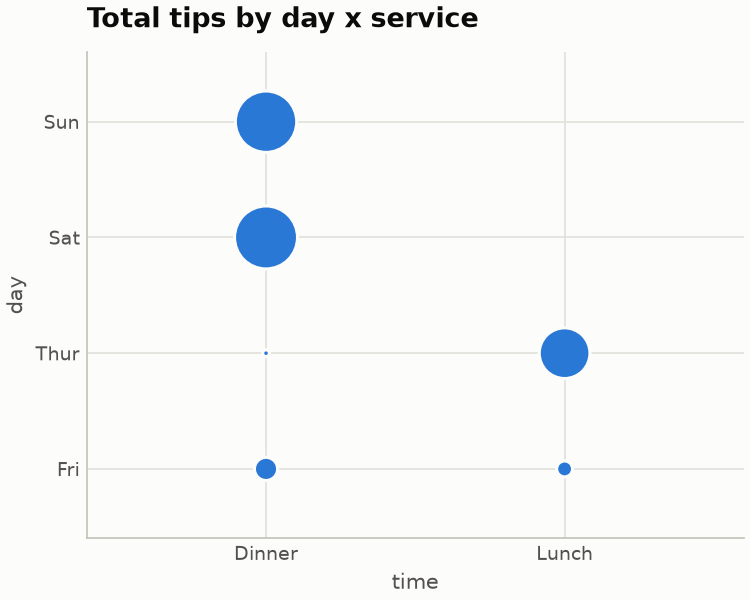

In [20]:
pc.matrix_chart(tips, 'day', 'time', 'tip', title='Total tips by day x service')

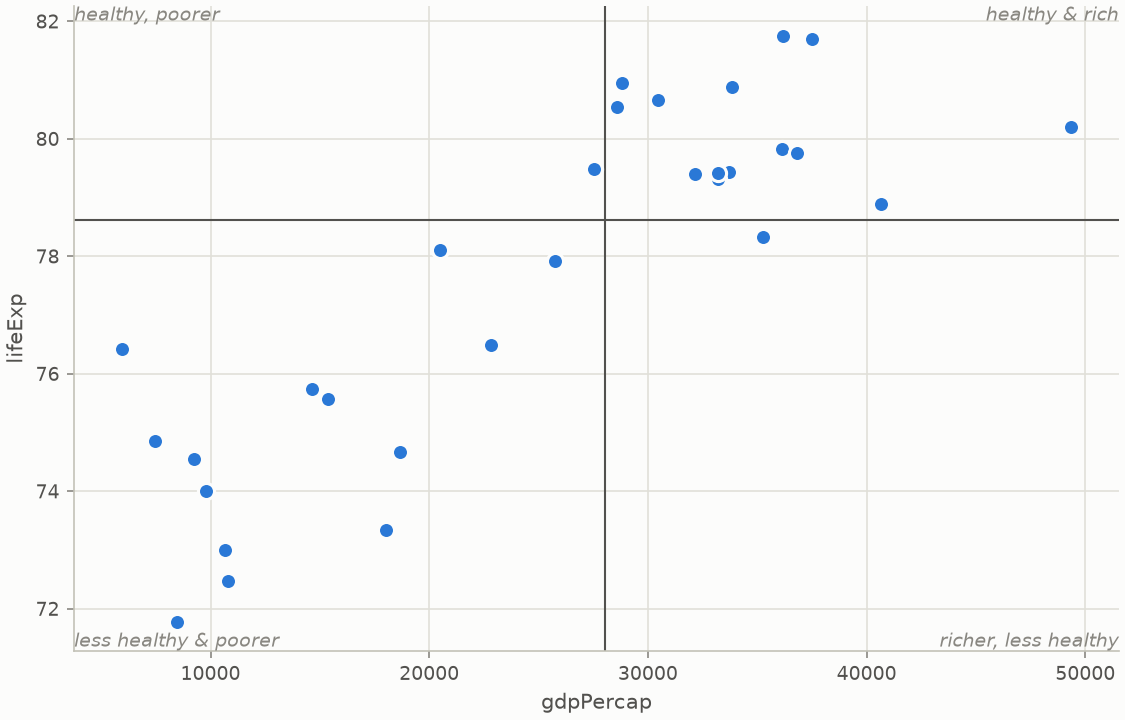

In [21]:
pc.quadrant(g07[g07.continent == 'Europe'], 'gdpPercap', 'lifeExp', 'country',
            quadrant_labels=('healthy, poorer', 'healthy & rich', 'less healthy & poorer', 'richer, less healthy'))